# Supplier Performance and Material Quality Analysis Using Apriori Association Rule Mining

## Case Study: Spiro Uganda

This notebook focuses on preparing supply chain data for association rule mining.

Due to confidentiality and availability limitations, a publicly available supply chain dataset was used to simulate supplier performance and material quality analytics within the operational context of Spiro Uganda.

Objectives:

- Understand the dataset
- Assess data quality
- Handle missing values
- Detect outliers
- Engineer supplier performance features
- Create transaction baskets for Apriori mining

Cell 2 – Import Libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

Cell 3 – Load Dataset

In [3]:
df = pd.read_csv("../data/raw/Supply_chain_dataset.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 3089
Columns: 22


,price_per_unit,quality_score,delivery_time_days,on_time_delivery_rate,defect_rate,return_rate,delivery_mode,lead_time_variance,forecast_accuracy,seasonality_index,demand_volatility_index,order_frequency_monthly,avg_order_volume,payment_term_days,offer_validity_days,procurement_action_code,delivery_term_code,items_requested,items_offered,temporal_month,supplier_reliability_score,selected_supplier_flag
0,218.54,3.28,13,0.82,0.01,0.04,Sea,2.67,0.64,1.03,0.03,15,3677.39,30,46,3,0,885,423,9,0.60,1
1,477.82,5.05,2,0.89,0.06,0.02,Road,1.68,0.85,0.84,0.27,44,4533.31,45,19,0,2,941,608,11,0.34,0
2,379.40,9.62,2,0.71,0.07,0.04,Sea,1.66,0.70,1.03,0.90,12,2983.06,90,58,2,2,746,683,1,0.33,0
3,319.40,4.59,15,0.72,0.02,0.02,Road,4.49,0.92,1.18,0.13,2,7687.09,90,15,3,2,275,890,3,0.87,1
4,120.21,8.56,23,0.84,0.04,0.05,Road,2.26,0.76,0.94,0.33,9,4154.52,45,11,3,0,171,895,1,0.54,0


## Dataset Structure

This section examines data types and identifies potential quality issues.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3089 entries, 0 to 3088
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   price_per_unit              3089 non-null   float64
 1   quality_score               3089 non-null   float64
 2   delivery_time_days          3089 non-null   int64  
 3   on_time_delivery_rate       3089 non-null   float64
 4   defect_rate                 3089 non-null   float64
 5   return_rate                 3089 non-null   float64
 6   delivery_mode               3089 non-null   str    
 7   lead_time_variance          3089 non-null   float64
 8   forecast_accuracy           3089 non-null   float64
 9   seasonality_index           3089 non-null   float64
 10  demand_volatility_index     3089 non-null   float64
 11  order_frequency_monthly     3089 non-null   int64  
 12  avg_order_volume            3089 non-null   float64
 13  payment_term_days           3089 non-null   

Cell 5 – Statistical Summary

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price_per_unit,3089.0,274.702813,131.094650,50.01,161.07,277.34,388.03,499.87
quality_score,3089.0,5.442768,2.589994,1.00,3.18,5.39,7.67,10.00
delivery_time_days,3089.0,14.961476,8.388526,1.00,8.00,15.00,22.00,29.00
on_time_delivery_rate,3089.0,0.848514,0.085293,0.70,0.78,0.85,0.92,1.00
defect_rate,3089.0,0.049887,0.029606,0.00,0.02,0.05,0.08,0.10
return_rate,3089.0,0.025238,0.015057,0.00,0.01,0.03,0.04,0.05
lead_time_variance,3089.0,2.504720,1.445600,0.00,1.26,2.47,3.79,5.00
forecast_accuracy,3089.0,0.800974,0.116458,0.60,0.70,0.80,0.90,1.00
seasonality_index,3089.0,1.003522,0.115444,0.80,0.90,1.01,1.10,1.20
demand_volatility_index,3089.0,0.502888,0.286257,0.00,0.26,0.50,0.75,1.00


## Missing Value Analysis

Missing values can affect mining results and must be identified before analysis.

Cell 7

In [6]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    'Column': missing.index,
    'Missing Values': missing.values
})

missing_df.sort_values(
    by='Missing Values',
    ascending=False
)

,Column,Missing Values
0,price_per_unit,0
1,quality_score,0
2,delivery_time_days,0
3,on_time_delivery_rate,0
4,defect_rate,0
5,return_rate,0
6,delivery_mode,0
7,lead_time_variance,0
8,forecast_accuracy,0
9,seasonality_index,0


Cell 8

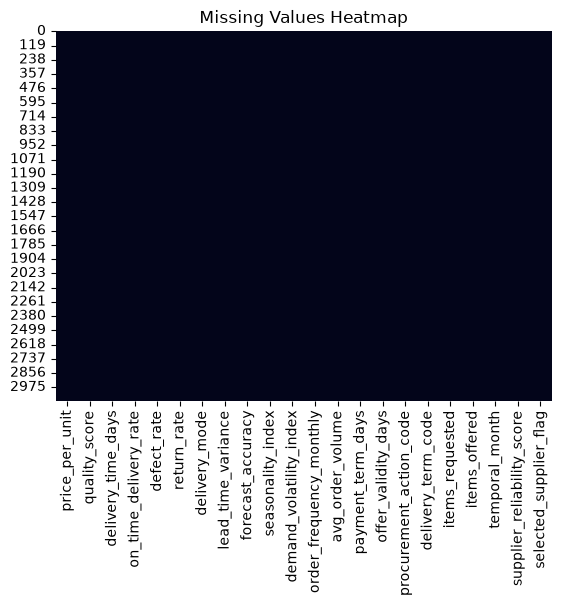

In [7]:
sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values Heatmap")
plt.show()

Cell 9

In [8]:
df = df.dropna()

print(df.shape)

(3089, 22)


## Outlier Detection

Outliers may distort supplier performance analysis.

Cell 11

In [9]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

numeric_cols

Index(['price_per_unit', 'quality_score', 'delivery_time_days',
       'on_time_delivery_rate', 'defect_rate', 'return_rate',
       'lead_time_variance', 'forecast_accuracy', 'seasonality_index',
       'demand_volatility_index', 'order_frequency_monthly',
       'avg_order_volume', 'payment_term_days', 'offer_validity_days',
       'procurement_action_code', 'delivery_term_code', 'items_requested',
       'items_offered', 'temporal_month', 'supplier_reliability_score',
       'selected_supplier_flag'],
      dtype='str')

Cell 12

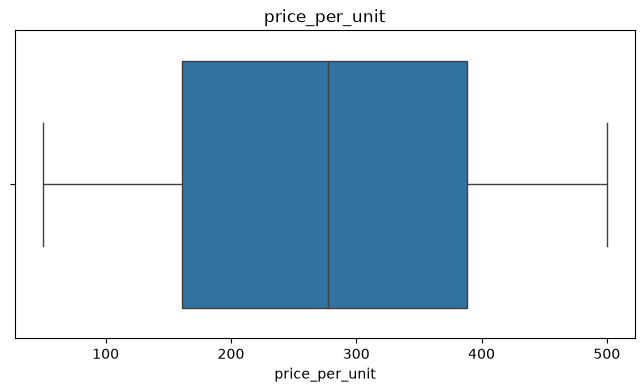

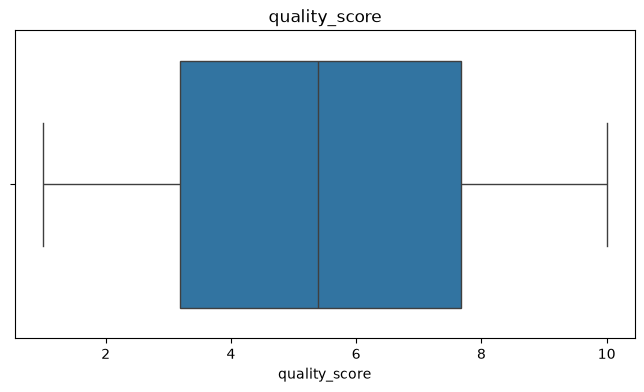

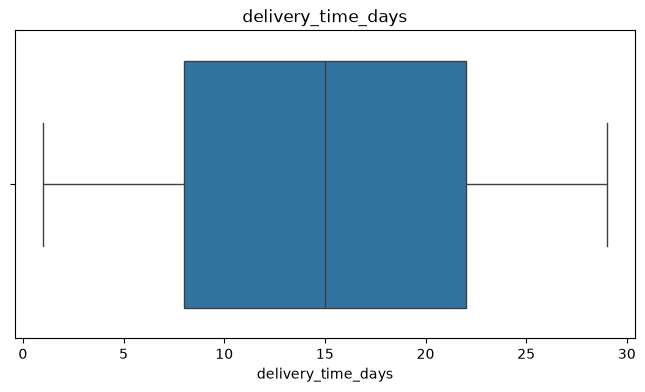

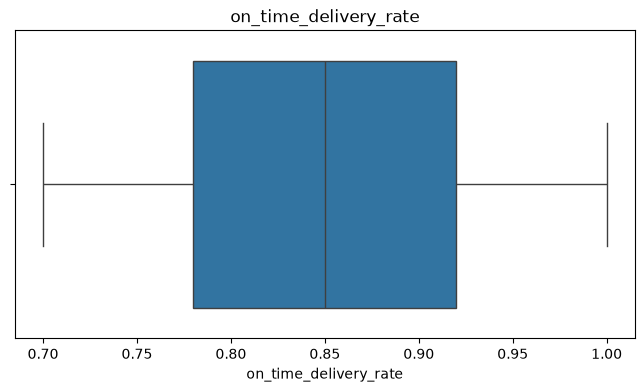

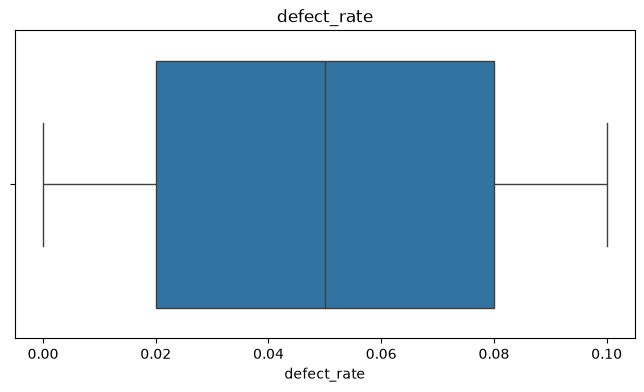

In [10]:
for col in numeric_cols[:5]:
    
    plt.figure(figsize=(8,4))
    
    sns.boxplot(x=df[col])
    
    plt.title(col)
    
    plt.show()

Cell 13 – IQR Outlier Treatment

In [11]:
def remove_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[
        (data[column] >= lower)
        &
        (data[column] <= upper)
    ]

Cell 14

In [12]:
df_clean = df.copy()

for col in [
    'quality_score',
    'defect_rate',
    'delivery_time_days',
    'supplier_reliability_score'
]:
    
    df_clean = remove_outliers_iqr(
        df_clean,
        col
    )

print(df_clean.shape)

(3089, 22)


## Feature Engineering

Continuous supplier metrics are converted into categorical business indicators suitable for association rule mining.

Cell 16 – Quality Category

In [13]:
df_clean['quality_category'] = pd.cut(
    df_clean['quality_score'],
    bins=[0,60,80,100],
    labels=[
        'Low_Quality',
        'Medium_Quality',
        'High_Quality'
    ]
)

Cell 17 – Defect Category

In [14]:
df_clean['defect_category'] = pd.cut(
    df_clean['defect_rate'],
    bins=[0,2,5,100],
    labels=[
        'Low_Defects',
        'Medium_Defects',
        'High_Defects'
    ]
)

Cell 18 – Reliability Category

In [15]:
df_clean['reliability_category'] = pd.cut(
    df_clean['supplier_reliability_score'],
    bins=[0,60,80,100],
    labels=[
        'Low_Reliability',
        'Medium_Reliability',
        'High_Reliability'
    ]
)

Cell 19 – Delivery Category

In [16]:
df_clean['delivery_category'] = pd.cut(
    df_clean['delivery_time_days'],
    bins=[0,5,10,100],
    labels=[
        'Fast_Delivery',
        'Moderate_Delivery',
        'Slow_Delivery'
    ]
)

Cell 20 – Supplier Selection Category

In [17]:
df_clean['selection_status'] = np.where(
    df_clean['selected_supplier_flag']==1,
    'Supplier_Selected',
    'Supplier_Not_Selected'
)

Verify Results

In [18]:
df_clean[[
    'quality_category',
    'defect_category',
    'reliability_category',
    'delivery_category',
    'selection_status'
]].head()

,quality_category,defect_category,reliability_category,delivery_category,selection_status
0,Low_Quality,Low_Defects,Low_Reliability,Slow_Delivery,Supplier_Selected
1,Low_Quality,Low_Defects,Low_Reliability,Fast_Delivery,Supplier_Not_Selected
2,Low_Quality,Low_Defects,Low_Reliability,Fast_Delivery,Supplier_Not_Selected
3,Low_Quality,Low_Defects,Low_Reliability,Slow_Delivery,Supplier_Selected
4,Low_Quality,Low_Defects,Low_Reliability,Slow_Delivery,Supplier_Not_Selected


## Transaction Construction

Each row is converted into a transaction containing supplier-performance attributes.

Cell 22

In [19]:
transactions = df_clean[[
    'quality_category',
    'defect_category',
    'reliability_category',
    'delivery_category',
    'selection_status'
]].astype(str)

transactions.head()

,quality_category,defect_category,reliability_category,delivery_category,selection_status
0,Low_Quality,Low_Defects,Low_Reliability,Slow_Delivery,Supplier_Selected
1,Low_Quality,Low_Defects,Low_Reliability,Fast_Delivery,Supplier_Not_Selected
2,Low_Quality,Low_Defects,Low_Reliability,Fast_Delivery,Supplier_Not_Selected
3,Low_Quality,Low_Defects,Low_Reliability,Slow_Delivery,Supplier_Selected
4,Low_Quality,Low_Defects,Low_Reliability,Slow_Delivery,Supplier_Not_Selected


Cell 23

In [ ]:
transactions.to_csv(
    "../data/processed/supplier_transactions.csv",
    index=False
)

print("Transactions Saved")